# k-Sensitivity — Plots and Summary
Run after both:
- `k_Sensitivity_Analysis` (6 methods) → `k_sensitivity.pkl`
- `k_Sensitivity_Fairlet_Only` (Fairlet) → `k_sensitivity_fairlet.pkl`

## Cell 1: Load and merge the two sweeps

In [3]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open('k_sensitivity.pkl', 'rb') as f:
    main = pickle.load(f)
with open('k_sensitivity_fairlet.pkl', 'rb') as f:
    sweep_fairlet = pickle.load(f)['sweep_fairlet']

sweep         = main['sweep']
dataset_names = main['datasets']
K_RANGE       = main['k_range']   
k_vals        = list(K_RANGE)

missing = [ds for ds in dataset_names if ds not in sweep_fairlet]
assert not missing, f"Fairlet results missing for: {missing}"
for ds in dataset_names:
    sweep[ds]['fairlet'] = sweep_fairlet[ds]

METHODS = ['kmeans', 'fairlet', 'bfkm', 'fair_centroid',
           'postprocessing_nfp', 'postprocessing_gini', 'rawlsian']
METHOD_LABEL = {'kmeans': 'K-Means', 'fairlet': 'Fairlet', 'bfkm': 'BFKM',
                'fair_centroid': 'CCF', 'postprocessing_nfp': 'PP-NFP',
                'postprocessing_gini': 'PP-Gini', 'rawlsian': 'Rawlsian'}
# colours in METHODS order: K-Means blue, Fairlet green, BFKM red, CCF purple, PP-NFP orange, PP-Gini brown, Rawlsian pink
COLORS = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#8c564b', '#e377c2']

# failed points (status != 'ok') would show as gaps in the plots
bad = [(ds, m, r['k'], r['status']) for ds in dataset_names for m in METHODS
       for r in sweep[ds][m] if r['status'] != 'ok']
print(f"✓ Loaded {len(dataset_names)} datasets x {len(METHODS)} methods x {len(k_vals)} k; "
      f"{len(bad)} failed point(s)")
for b in bad:
    print("   ", b)

# merged file, for the record
with open('k_sensitivity_merged.pkl', 'wb') as f:
    pickle.dump({'sweep': sweep, 'datasets': dataset_names,
                 'methods': METHODS, 'k_range': k_vals}, f)
print("✓ Saved: k_sensitivity_merged.pkl")

✓ Loaded 18 datasets x 7 methods x 9 k; 0 failed point(s)
✓ Saved: k_sensitivity_merged.pkl


## Cell 2: Silhouette-optimal k of each method (Section 3.4 boundary check)

In [5]:
best_k = {ds: {m: k_vals[int(np.nanargmax([r['Silhouette'] for r in sweep[ds][m]]))]
               for m in METHODS} for ds in dataset_names}

_all = [best_k[ds][m] for ds in dataset_names for m in METHODS]
n_tot, n_lo, n_hi = len(_all), _all.count(k_vals[0]), _all.count(k_vals[-1])
print(f"Silhouette-optimal k over {n_tot} dataset-method combinations:")
print(f"  {n_tot - n_hi}/{n_tot} ({100*(n_tot - n_hi)/n_tot:.1f}%) below the upper boundary k={k_vals[-1]}")
print(f"  {n_hi} at k={k_vals[-1]}: "
      f"{[(ds, METHOD_LABEL[m]) for ds in dataset_names for m in METHODS if best_k[ds][m] == k_vals[-1]]}")
print(f"  {n_lo} at k={k_vals[0]}")

best_k_df = pd.DataFrame(best_k).T[METHODS].rename(columns=METHOD_LABEL)
best_k_df

Silhouette-optimal k over 126 dataset-method combinations:
  107/126 (84.9%) below the upper boundary k=10
  19 at k=10: [('compas', 'K-Means'), ('compas', 'BFKM'), ('compas', 'CCF'), ('compas', 'PP-NFP'), ('compas', 'PP-Gini'), ('compas', 'Rawlsian'), ('german', 'Rawlsian'), ('compas_race', 'K-Means'), ('compas_race', 'CCF'), ('compas_race', 'PP-NFP'), ('compas_race', 'PP-Gini'), ('compas_race', 'Rawlsian'), ('compas_combined', 'K-Means'), ('compas_combined', 'CCF'), ('compas_combined', 'PP-NFP'), ('compas_combined', 'PP-Gini'), ('compas_combined', 'Rawlsian'), ('dutch_gender', 'BFKM'), ('dutch_gender', 'Rawlsian')]
  42 at k=2


,K-Means,Fairlet,BFKM,CCF,PP-NFP,PP-Gini,Rawlsian
adult,9,2,3,3,9,9,4
compas,10,2,10,10,10,10,10
german,5,2,2,2,2,5,10
credit,2,2,2,2,2,2,2
law,3,2,2,3,3,3,2
adult_race,9,2,3,2,9,9,6
adult_combined,9,2,3,3,9,9,5
compas_race,10,2,9,10,10,10,10
compas_combined,10,2,9,10,10,10,10
law_race,3,2,2,3,3,3,2


## Plot style (shared by all figures)

In [7]:
# Plot style shared by all figures below
def ds_title(ds):
    """'adult' -> 'Adult_gender', 'law_race' -> 'Law_race', 'meps_combined' -> 'Meps_comb'."""
    base, _, attr = ds.partition('_')
    attr = {'': 'gender', 'combined': 'comb'}.get(attr, attr)
    return f"{base.capitalize()}_{attr}"

TITLE_FS, LABEL_FS, TICK_FS = 20, 15, 11.5
LEGEND_FS, LEGEND_TITLE_FS  = 13, 15
LINE_W, MARKER_S, STAR_S    = 1.7, 4.5, 14

def style_ax(ax, title, ylabel):
    ax.set_title(title, fontsize=TITLE_FS, fontweight='bold', pad=18)  
    ax.set_xlabel('k', fontsize=LABEL_FS)
    ax.set_ylabel(ylabel, fontsize=LABEL_FS)
    ax.set_xticks(k_vals)
    ax.tick_params(labelsize=TICK_FS)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.spines[['top', 'right']].set_visible(False)

def plot_method(ax, ds, method, ci, metric, star):
    y = [r[metric] for r in sweep[ds][method]]
    ax.plot(k_vals, y, marker='o', markersize=MARKER_S, linewidth=LINE_W,
            color=COLORS[ci], label=METHOD_LABEL[method])
    if star:                                                 # star = this method's Silhouette optimum
        kb = best_k[ds][method]
        ax.plot(kb, y[k_vals.index(kb)], marker='*', markersize=STAR_S, color=COLORS[ci],
                markeredgecolor='black', markeredgewidth=0.7, zorder=5)

def add_legend(fig, axes_flat, **kw):
    handles, labels_ = axes_flat[0].get_legend_handles_labels()
    fig.legend(handles, labels_, ncol=4, fontsize=LEGEND_FS, title='Algorithm',
               title_fontsize=LEGEND_TITLE_FS, framealpha=0.9, **kw)

## Cell 3: Silhouette, Balance, SPD vs k (one row per dataset)

✓ Saved: k_sensitivity_all.png / .pdf


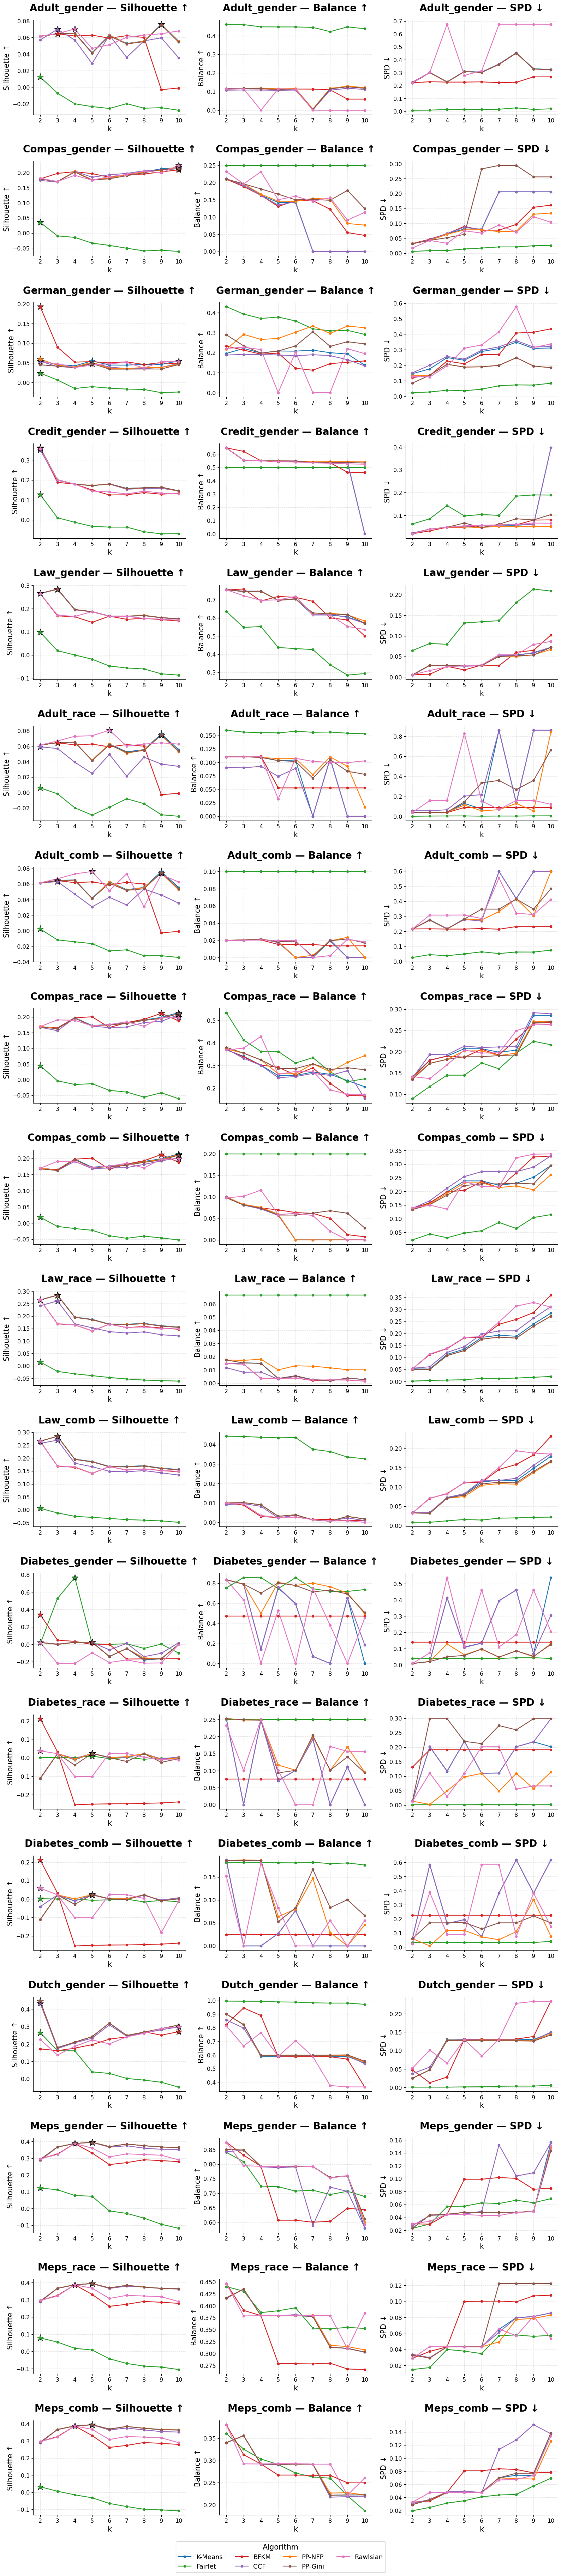

In [9]:
metrics_to_plot = [('Silhouette', 'Silhouette ↑'), ('Balance', 'Balance ↑'), ('SPD', 'SPD ↓')]

n_ds = len(dataset_names)
fig, axes = plt.subplots(n_ds, 3, figsize=(16, 4.0*n_ds), squeeze=False)

for di, ds in enumerate(dataset_names):
    for mi, (metric, label) in enumerate(metrics_to_plot):
        ax = axes[di][mi]
        for ci, method in enumerate(METHODS):
            plot_method(ax, ds, method, ci, metric, star=(metric == 'Silhouette'))
        style_ax(ax, f'{ds_title(ds)} — {label}', label)

plt.tight_layout(h_pad=2.5)
add_legend(fig, axes.ravel(), loc='upper center', bbox_to_anchor=(0.5, 0.0))
plt.savefig('k_sensitivity_all.png', dpi=800, bbox_inches='tight')
plt.savefig('k_sensitivity_all.pdf', bbox_inches='tight')
print("✓ Saved: k_sensitivity_all.png / .pdf")
plt.show()

## Cell 4: Silhouette vs k — compact grid (paper-ready)

✓ Saved: k_sensitivity_FigS1_Silhouette.png / .pdf


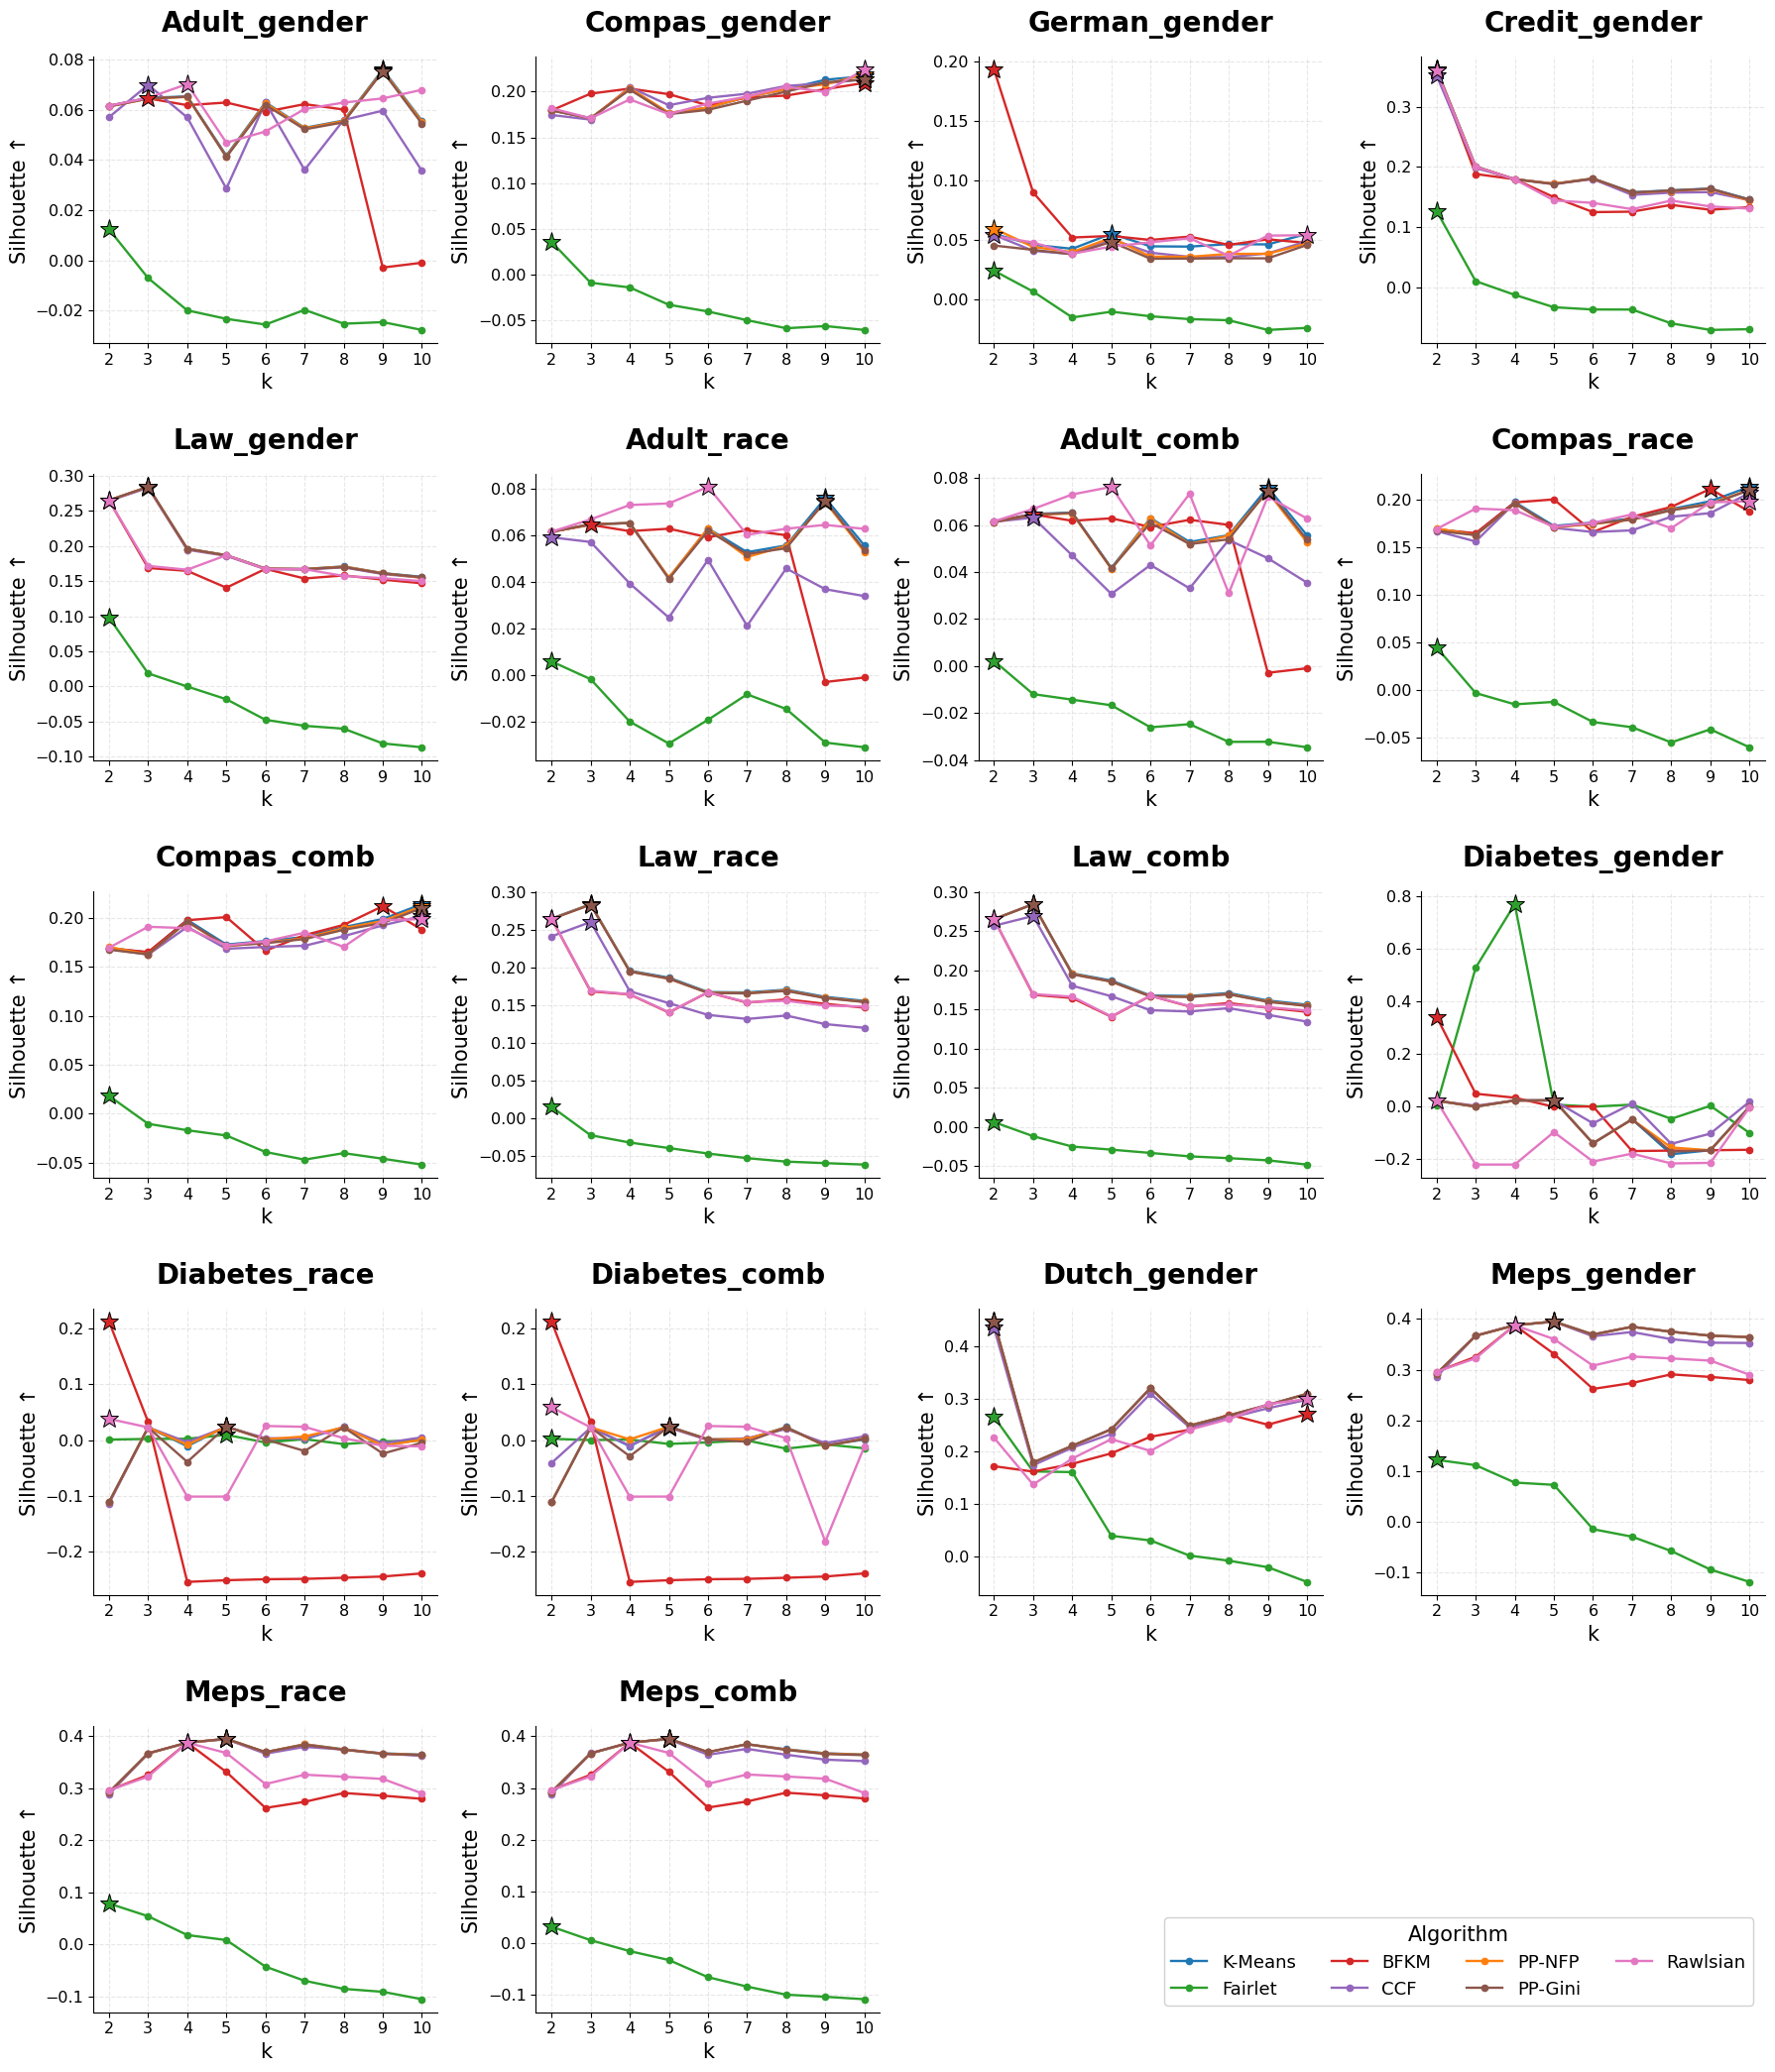

✓ Saved: k_sensitivity_FigS2_Balance.png / .pdf


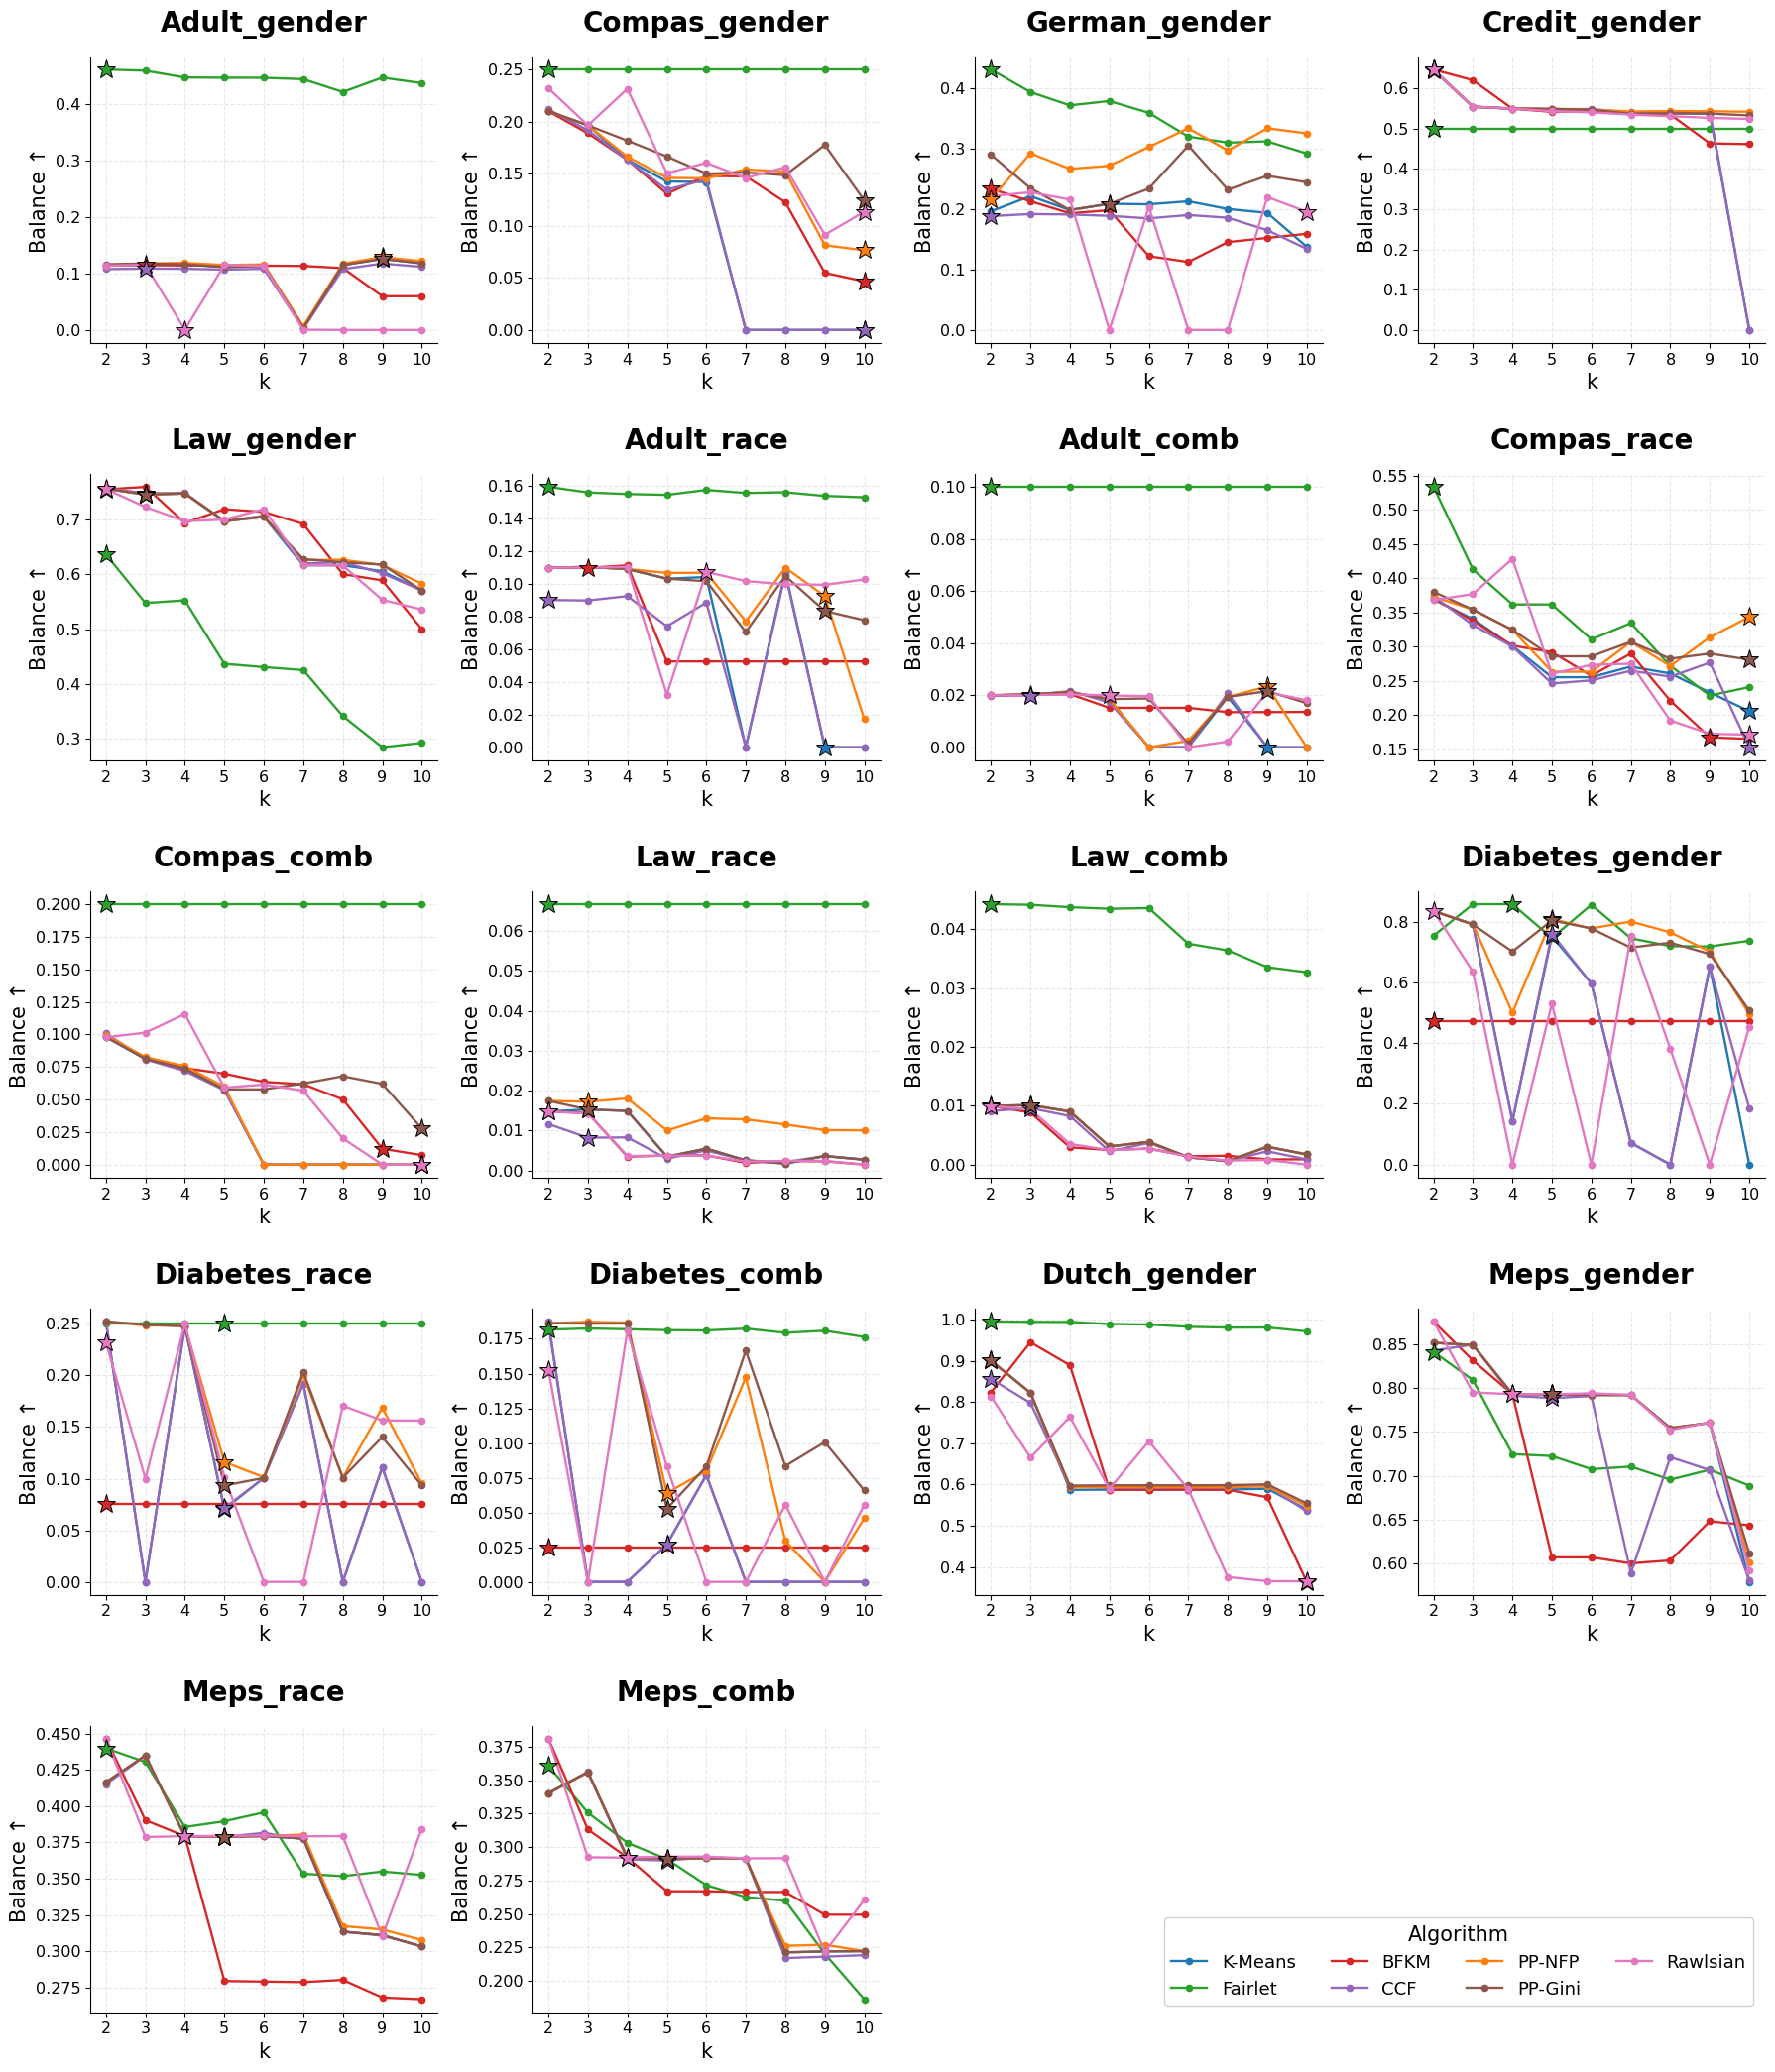

✓ Saved: k_sensitivity_FigS3_SPD.png / .pdf


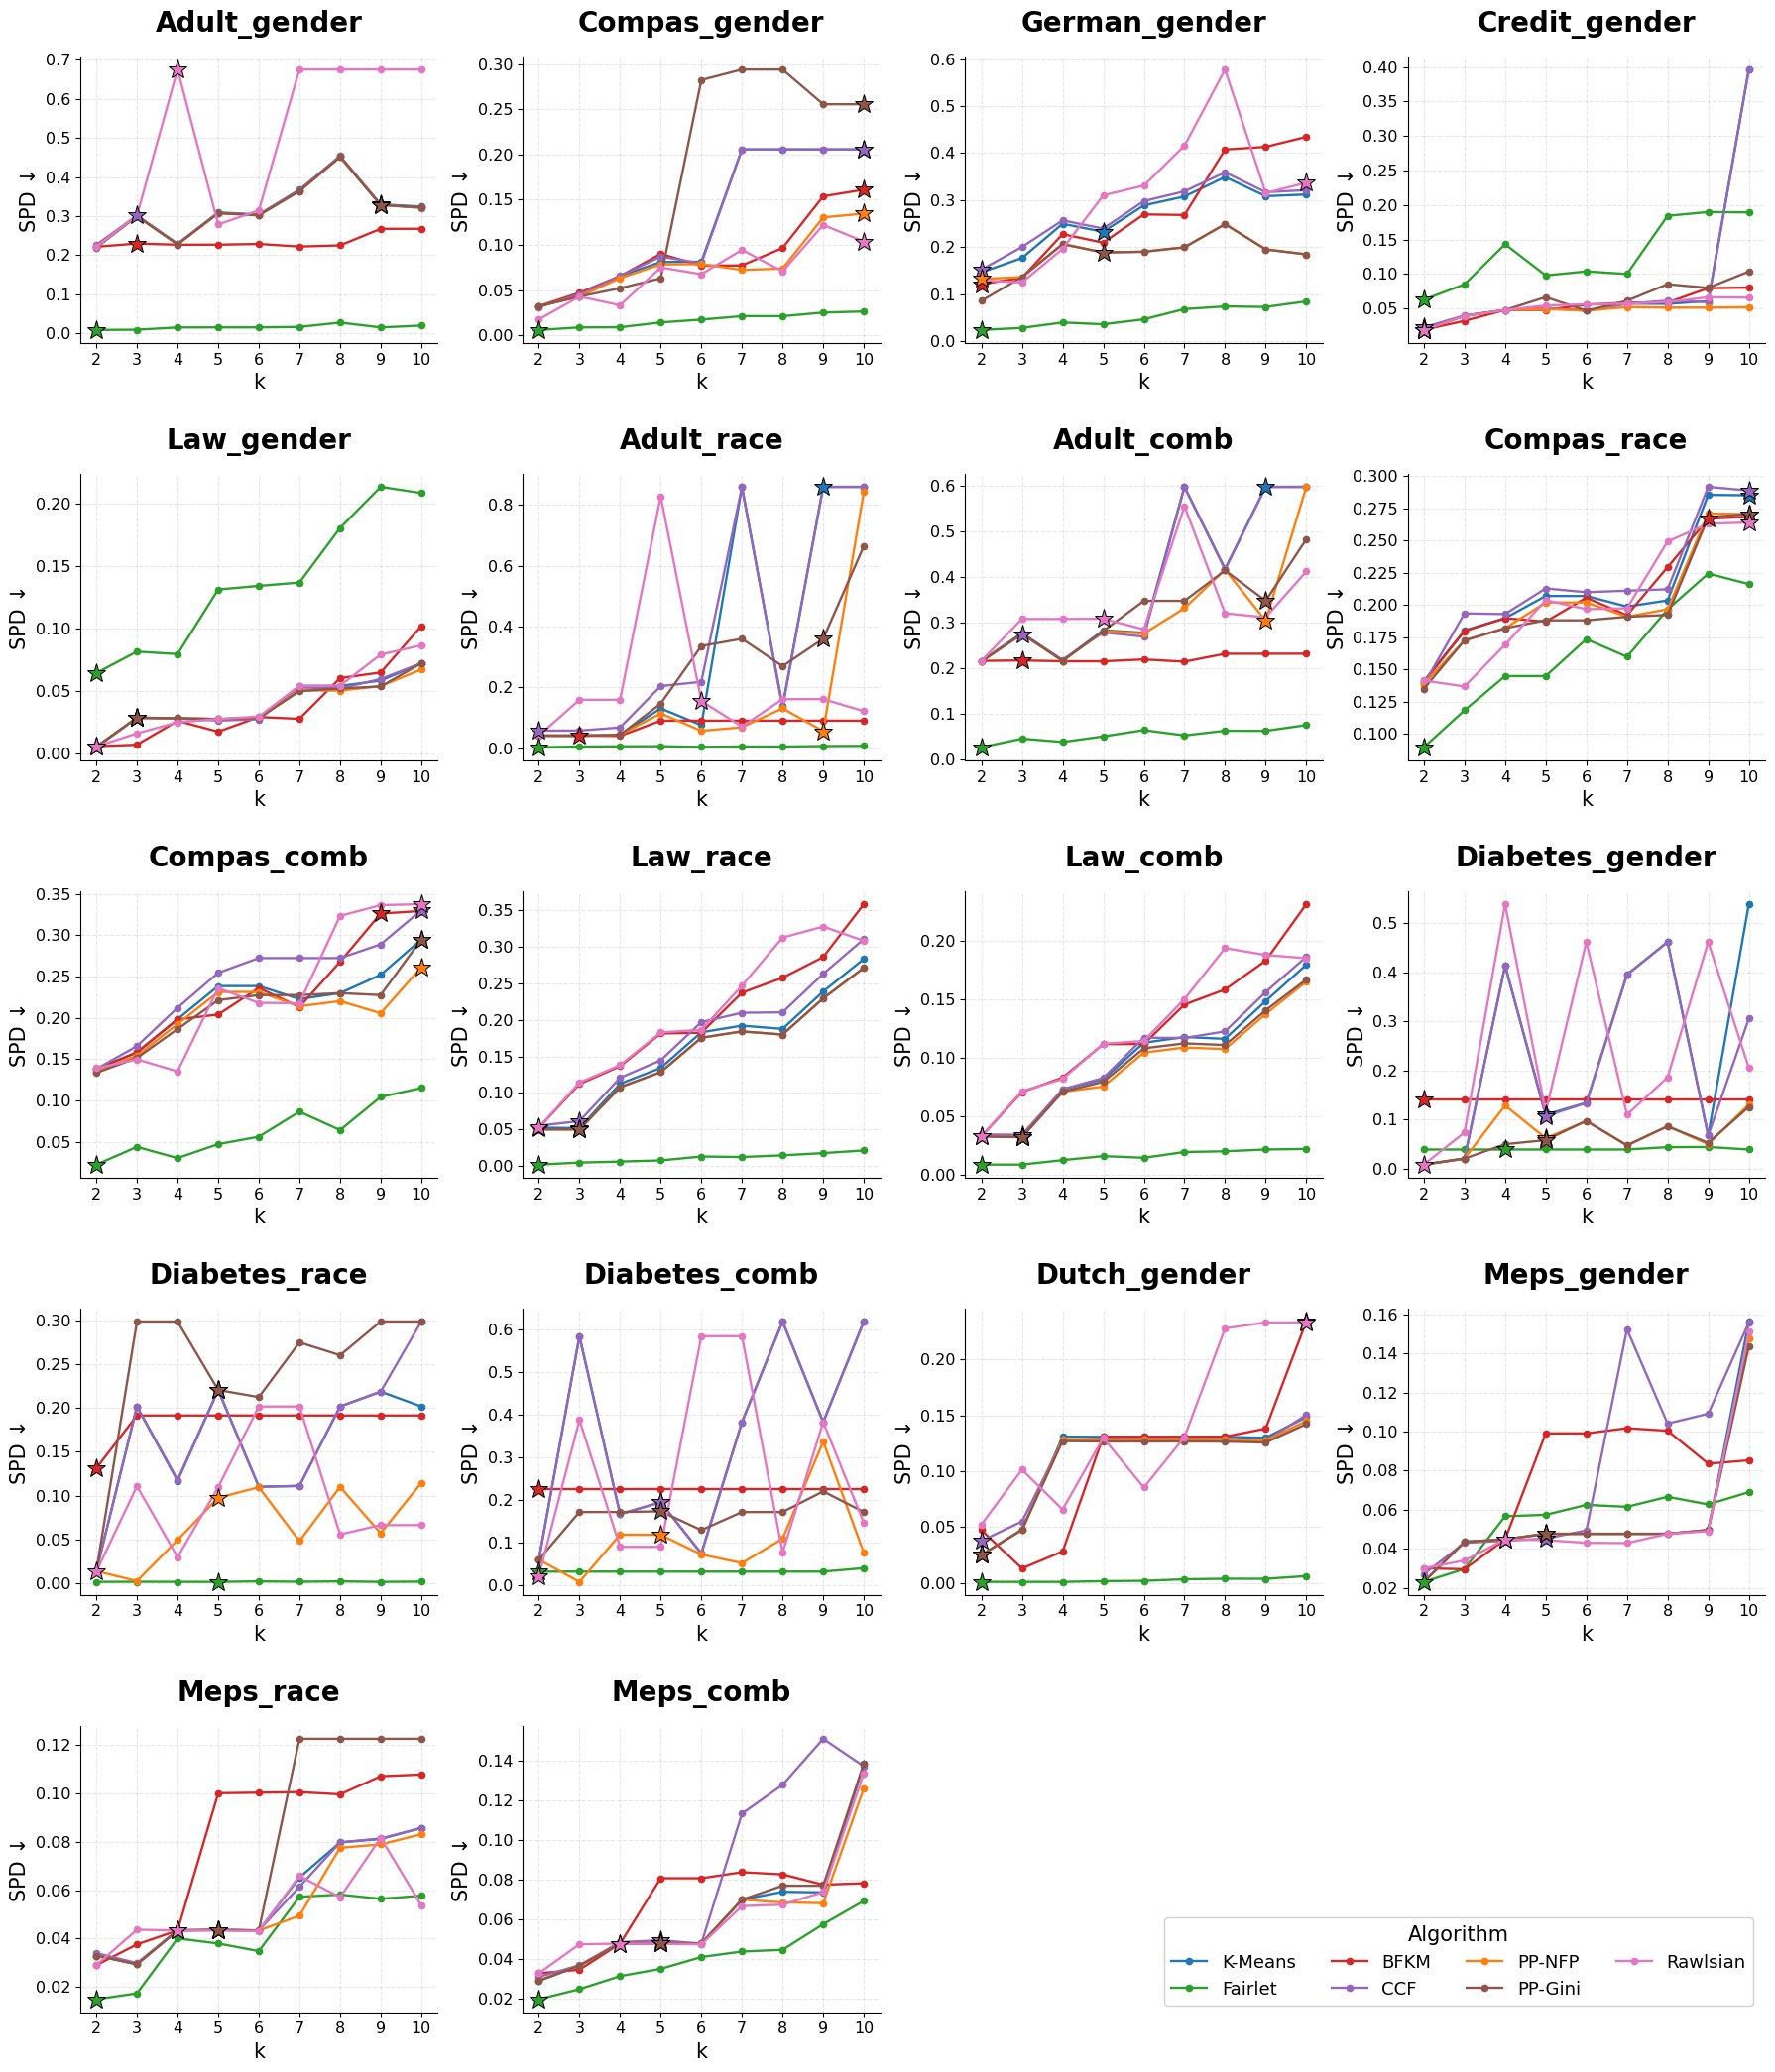

In [11]:
N_COLS = 4
N_ROWS = -(-len(dataset_names) // N_COLS)
for tag, metric, label in [('S1', 'Silhouette', 'Silhouette ↑'),
                           ('S2', 'Balance',    'Balance ↑'),
                           ('S3', 'SPD',        'SPD ↓')]:
    fig2, axes2 = plt.subplots(N_ROWS, N_COLS, figsize=(18, 4.2*N_ROWS), squeeze=False)
    for di, ds in enumerate(dataset_names):
        ax = axes2[di // N_COLS][di % N_COLS]
        for ci, method in enumerate(METHODS):
            plot_method(ax, ds, method, ci, metric, star=True)
        style_ax(ax, ds_title(ds), label)
    for di in range(len(dataset_names), N_ROWS * N_COLS):
        axes2[di // N_COLS][di % N_COLS].axis('off')
    plt.tight_layout(h_pad=2.5)
    add_legend(fig2, axes2.ravel(), loc='lower right', bbox_to_anchor=(0.99, 0.03))
    plt.savefig(f'k_sensitivity_Fig{tag}_{metric}.png', dpi=200, bbox_inches='tight')
    plt.savefig(f'k_sensitivity_Fig{tag}_{metric}.pdf', bbox_inches='tight')
    print(f"✓ Saved: k_sensitivity_Fig{tag}_{metric}.png / .pdf")
    plt.show()

## Cell 4b: Representative datasets — 2 × 3 (Fig. 5a)

✓ Saved: k_sensitivity_fig5a.png / .pdf


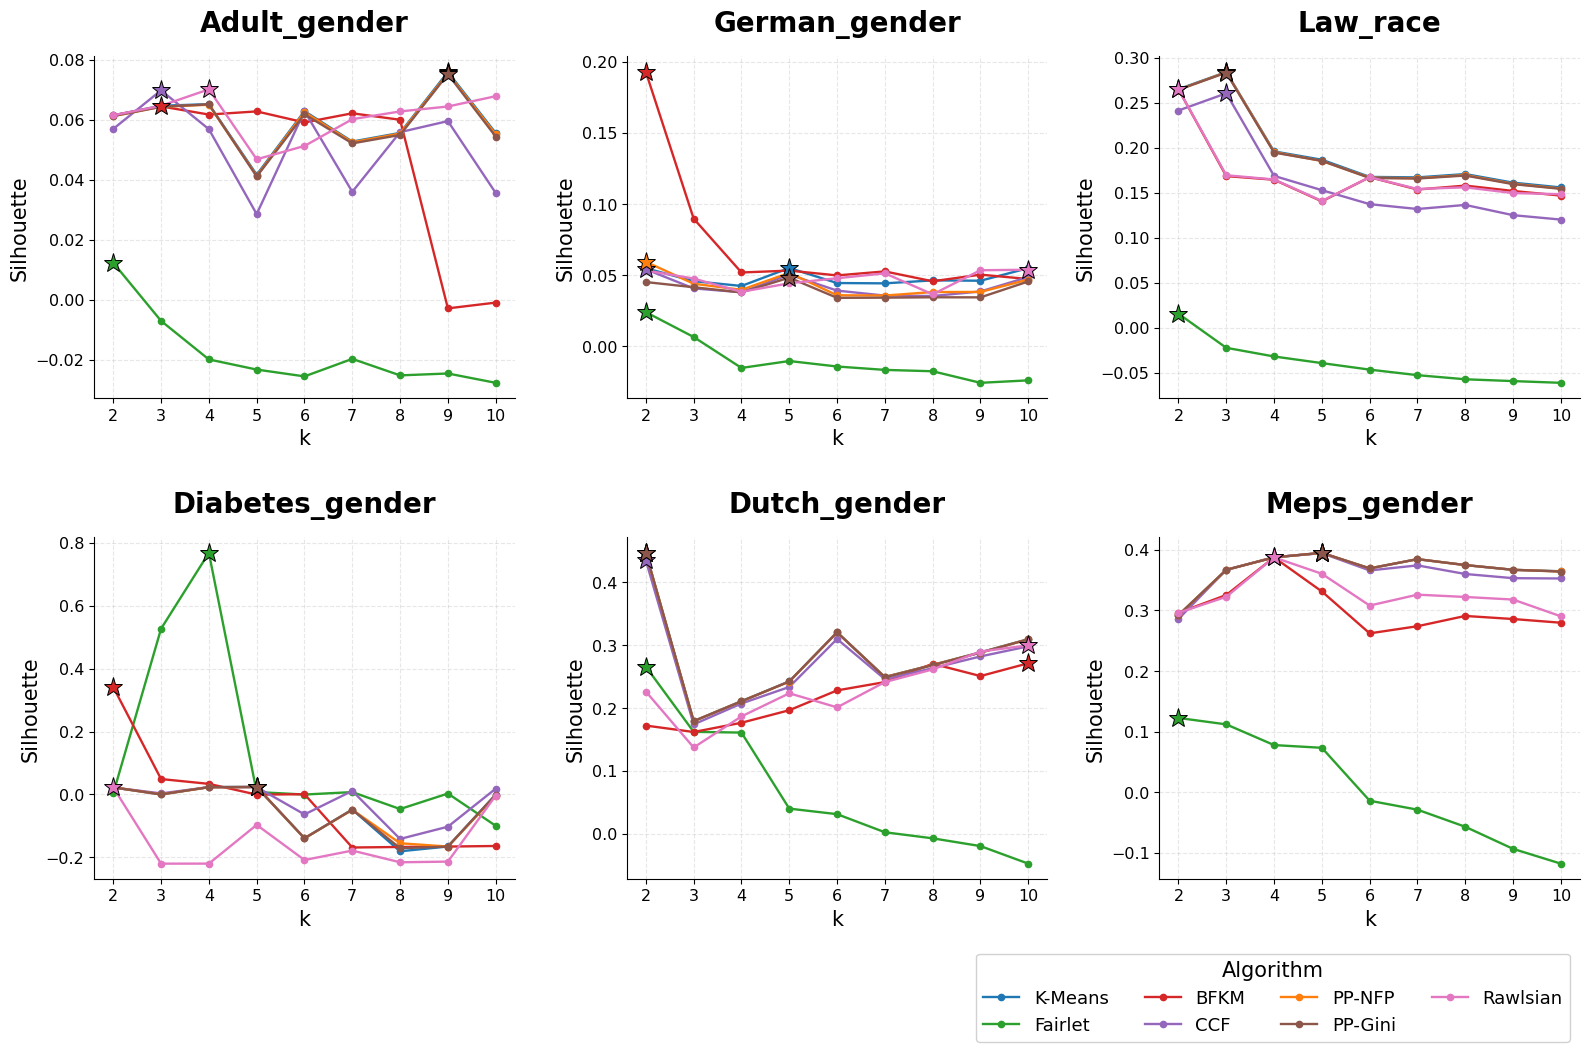

In [13]:
# Representative datasets (2 x 3), as in Fig. 5a; change REP to pick other configurations
REP = ['adult', 'german', 'law_race', 'diabetes_gender', 'dutch_gender', 'meps_gender']

fig3, axes3 = plt.subplots(2, 3, figsize=(16, 9.5), squeeze=False)
for di, ds in enumerate(REP):
    ax = axes3[di // 3][di % 3]
    for ci, method in enumerate(METHODS):
        plot_method(ax, ds, method, ci, 'Silhouette', star=True)
    style_ax(ax, ds_title(ds), 'Silhouette')

plt.tight_layout(h_pad=3.0, w_pad=2.0)
add_legend(fig3, axes3.ravel(), loc='upper right', bbox_to_anchor=(0.99, 0.0))
plt.savefig('k_sensitivity_fig5a.png', dpi=800, bbox_inches='tight')
plt.savefig('k_sensitivity_fig5a.pdf', bbox_inches='tight')
print("✓ Saved: k_sensitivity_fig5a.png / .pdf")
plt.show()

✓ Saved: k_sensitivity_fig5b_balance.png / .pdf


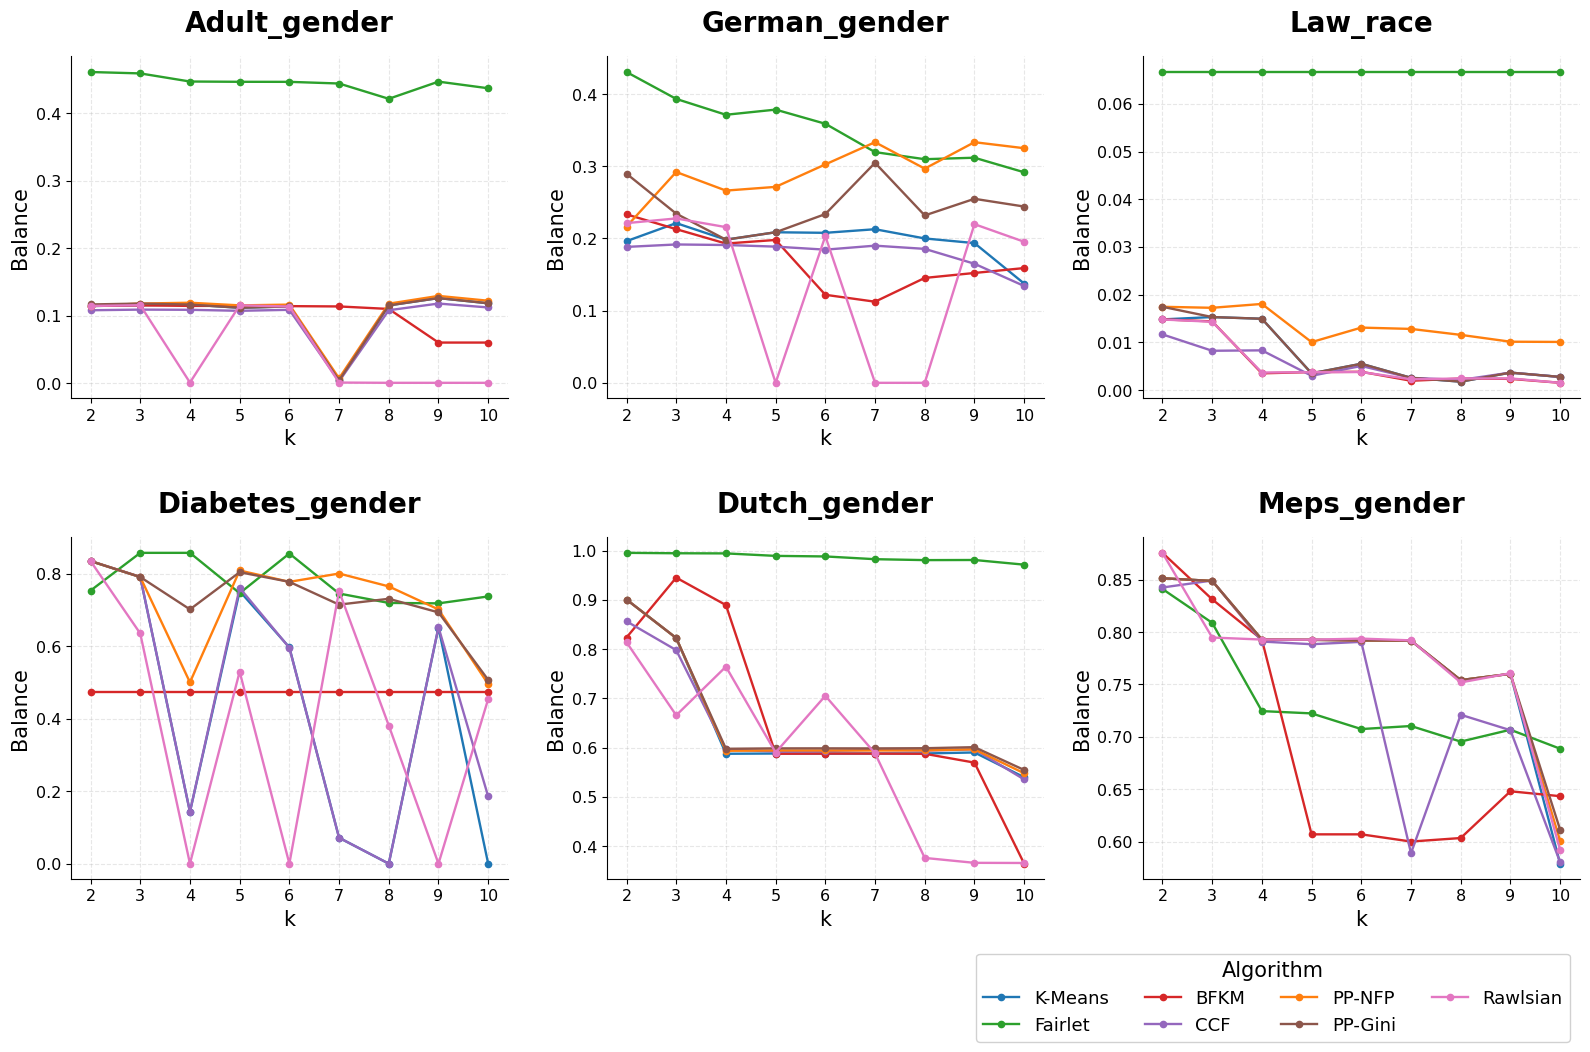

✓ Saved: k_sensitivity_fig5c_spd.png / .pdf


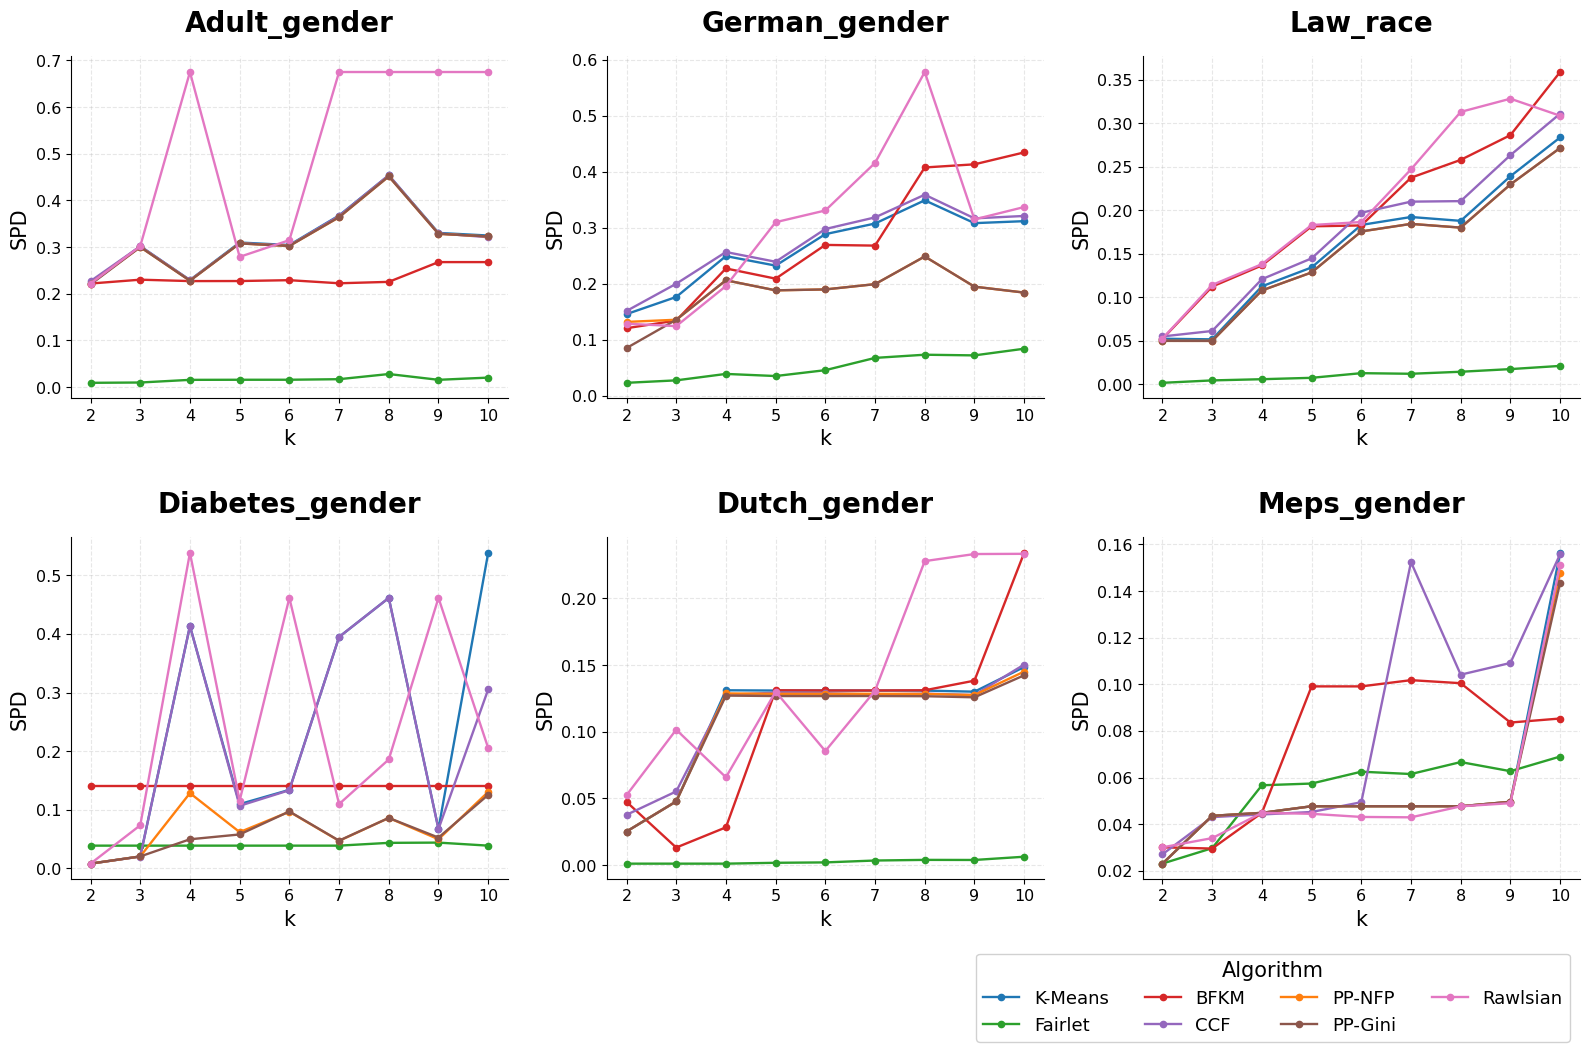

In [14]:
# Balance and SPD vs k for the same representative datasets (2 x 3), same style as Fig. 5a
for metric, ylabel, fname in [('Balance', 'Balance', 'k_sensitivity_fig5b_balance'),
                              ('SPD',     'SPD',     'k_sensitivity_fig5c_spd')]:
    fig4, axes4 = plt.subplots(2, 3, figsize=(16, 9.5), squeeze=False)
    for di, ds in enumerate(REP):
        ax = axes4[di // 3][di % 3]
        for ci, method in enumerate(METHODS):
            plot_method(ax, ds, method, ci, metric, star=False)   # no star: the optimum is defined on Silhouette
        style_ax(ax, ds_title(ds), ylabel)

    plt.tight_layout(h_pad=3.0, w_pad=2.0)
    add_legend(fig4, axes4.ravel(), loc='upper right', bbox_to_anchor=(0.99, 0.0))
    plt.savefig(f'{fname}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'{fname}.pdf', bbox_inches='tight')
    print(f"✓ Saved: {fname}.png / .pdf")
    plt.show()

## Cell 5: Summary table

In [16]:
rows = []
for ds in dataset_names:
    for method in METHODS:
        res = {r['k']: r for r in sweep[ds][method]}
        kb = best_k[ds][method]
        rows.append({'Dataset': ds, 'Method': METHOD_LABEL[method], 'Best_k': kb,
                     'Sil@k=2':    round(res[2]['Silhouette'], 4),
                     'Sil@best_k': round(res[kb]['Silhouette'], 4),
                     'Sil@k=10':   round(res[10]['Silhouette'], 4),
                     'Bal@best_k': round(res[kb]['Balance'], 4),
                     'SPD@best_k': round(res[kb]['SPD'], 4)})
sens_df = pd.DataFrame(rows)
sens_df.to_csv('k_sensitivity_summary.csv', index=False)
best_k_df.to_csv('k_sensitivity_best_k.csv')
print("✓ Saved: k_sensitivity_summary.csv, k_sensitivity_best_k.csv")
sens_df

✓ Saved: k_sensitivity_summary.csv, k_sensitivity_best_k.csv


,Dataset,Method,Best_k,Sil@k=2,Sil@best_k,Sil@k=10,Bal@best_k,SPD@best_k
0,adult,K-Means,9,0.0615,0.0760,0.0556,0.1260,0.3302
1,adult,Fairlet,2,0.0123,0.0123,-0.0277,0.4611,0.0090
2,adult,BFKM,3,0.0615,0.0645,-0.0009,0.1152,0.2300
3,adult,CCF,3,0.0570,0.0698,0.0356,0.1089,0.3015
4,adult,PP-NFP,9,0.0613,0.0755,0.0552,0.1292,0.3283
...,...,...,...,...,...,...,...,...
121,meps_combined,BFKM,4,0.2961,0.3876,0.2797,0.2921,0.0478
122,meps_combined,CCF,5,0.2878,0.3941,0.3519,0.2900,0.0495
123,meps_combined,PP-NFP,5,0.2921,0.3950,0.3644,0.2916,0.0479
124,meps_combined,PP-Gini,5,0.2921,0.3950,0.3635,0.2916,0.0479
